# MyoSuite with a TD-MPC2 baseline

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/envs/myosuite.ipynb)

[MyoSuite](https://github.com/MyoHub/myosuite) drives musculoskeletal models with muscle activations. Here the task is `myoFingerReachRandom-v0`: bring a fingertip, driven by five muscles, to a target sampled at every reset. Rewards are MyoSuite's dense rewards, and an episode succeeds if MyoSuite's `solved` flag is raised at any step.

The baseline is [TD-MPC2](../../docs/models/tdmpc/tdmpc2.md), the model these suites were benchmarked with: an encoder, latent dynamics, a reward head, an ensemble of Q-functions and a policy prior, learned online from what the agent collects, with no decoder. MPPI searches action sequences in its latent space. This is a deliberately small run: a 128-dimensional latent, state observations and 20,000 updates, not the paper's millions.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,myosuite]"

In [1]:
import time

import torch

from torch_world import plots
from torch_world.envs import MyoSuite
from torch_world.models import TDMPC2
from torch_world.models.tdmpc import state_encoder
from torch_world.planning import MPPI

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
TASK, ENVS, HORIZON = "myoFingerReachRandom-v0", 16, 3
world = MyoSuite(TASK, batch_size=ENVS, terminate_on_success=False, render_size=128)
EPISODE, A, D = world.max_episode_steps, world.action_dim, world.state.shape[-1]
print(f"{EPISODE}-step episodes, {D} state dimensions, {A} actions")

100-step episodes, 19 state dimensions, 5 actions


## The task

MyoSuite needs MuJoCo 3.7 or later, so it is installed apart from the `benchmark` extra. Episodes run to the time limit, as in TD-MPC2's own evaluations, instead of ending at success: the rewards are dense and highest near the goal, so ending the episode there would cut off the reward a return-maximizing planner is after. 16 episodes run in parallel, one per batch lane; each lane is seeded separately. The first frames of four lanes:

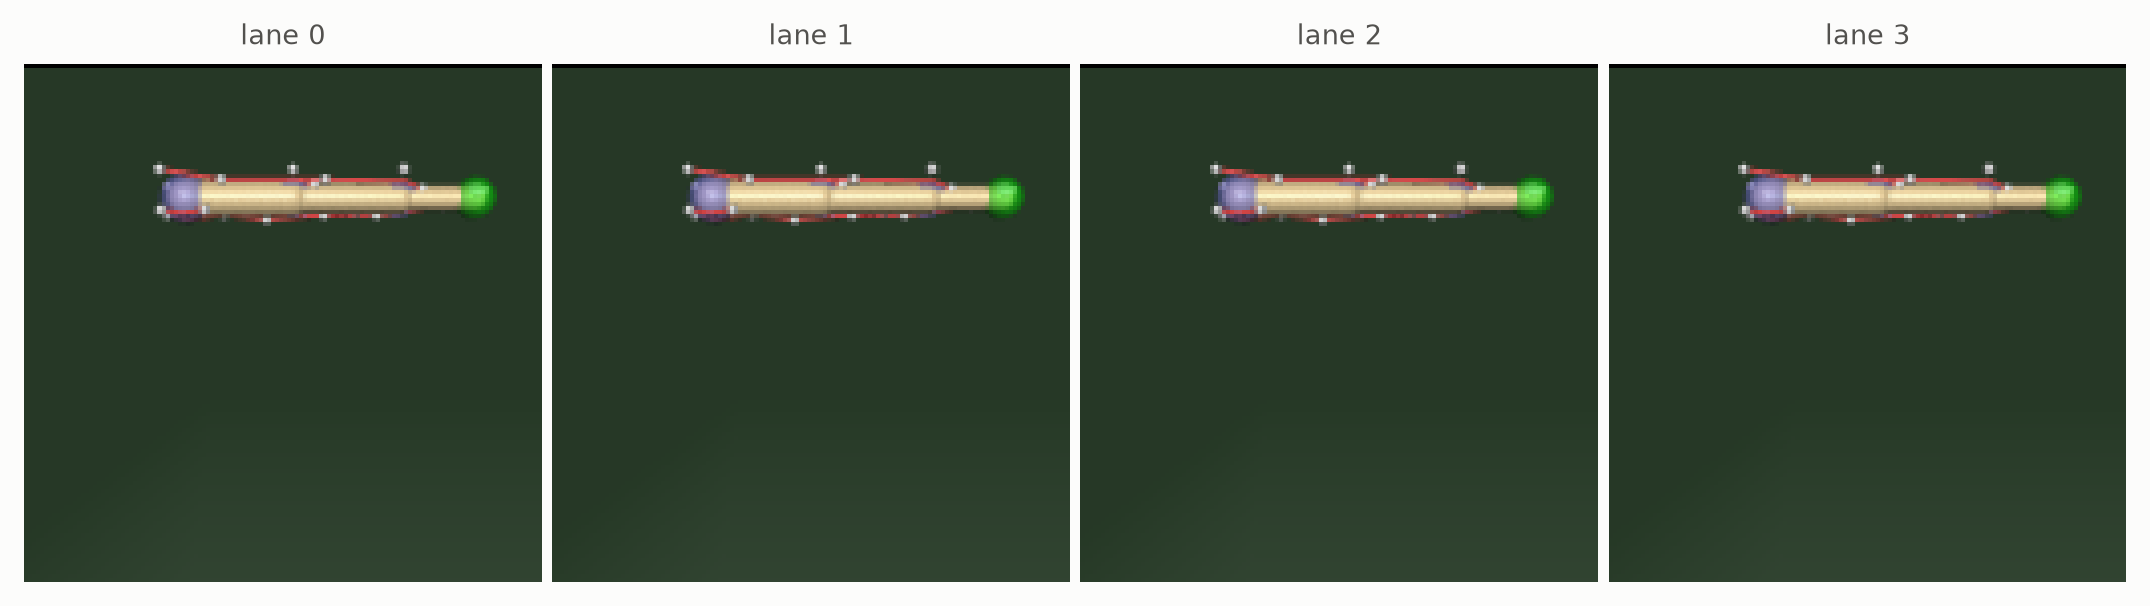

In [2]:
world.reset(seed=0)
plots.images(world.render_frame()[:4], [f"lane {i}" for i in range(4)], ncols=4, size=2.2)

## Model and planner

A small TD-MPC2: 128-dimensional SimNorm latents, 256-unit MLPs and the paper's five Q-functions, with the reference's discount for this episode length. MPPI plans 3 steps ahead with 256 sequences, 12 of them proposed by the policy prior, and starts each call from the previous plan shifted by one step.

In [3]:
model = TDMPC2(
    state_encoder(D, latent_dim=128, hidden_dim=256), action_dim=A, latent_dim=128, mlp_dim=256,
    discount=TDMPC2.episode_discount(EPISODE), episodic=False,
).to(device)
opt = torch.optim.Adam(model.param_groups(3e-4))
planner = MPPI(horizon=HORIZON, action_dim=A, num_samples=256, num_elites=32, num_pi_trajs=12, iterations=4)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M parameters, discount {model.discount:.3f}")

1.04M parameters, discount 0.950


## Online training

Each round collects 16 episodes in parallel, then takes 500 gradient steps on windows of `HORIZON + 1` steps from all episodes so far. Windows never cross the end of an episode: a lane that finished is padding, `valid=False`, until the next reset. The first round acts at random; after that, MPPI acts, with exploration noise from its own final std.

round   0  return    -9.7  success 0.12    0.3 min


round   4  return   379.8  success 1.00    1.9 min


round   8  return   466.6  success 1.00    3.3 min


round  12  return   637.6  success 1.00    5.0 min


round  16  return   799.0  success 1.00    6.4 min


...

round  24  return   798.7  success 1.00    9.9 min


round  28  return   796.6  success 1.00   11.9 min


round  32  return   799.2  success 1.00   13.9 min


round  36  return   799.1  success 1.00   17.0 min


round  39  return   798.0  success 1.00   19.3 min


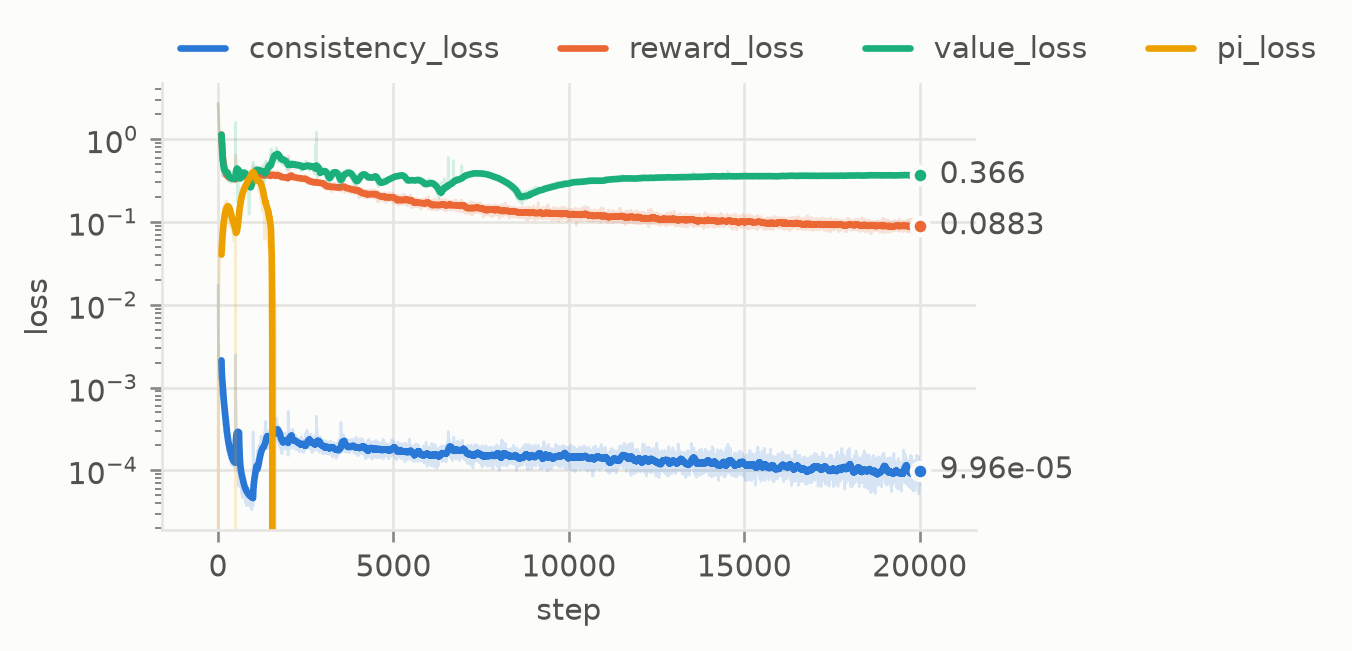

In [4]:
buffer = {k: [] for k in ("obs", "actions", "rewards", "terminated", "valid")}


def collect(policy, seed, frames=0):
    """Run one episode per lane; store it, and return its return, success and the first lanes' frames."""
    obs = world.reset(seed=seed)
    planner.reset()
    data = {k: [] for k in buffer}
    data["obs"].append(obs)
    returns, success = torch.zeros(ENVS), torch.zeros(ENVS, dtype=torch.bool)
    video = [world.render_frame()[:frames]] if frames else []
    while not world.transition.done.all():
        active = ~world.transition.done
        action = policy(obs)
        obs = world.step(action)
        t = world.transition
        for key, value in zip(data, (obs, action, t.reward, t.terminated & active, active)):
            data[key].append(value)
        returns += t.reward * active
        if t.success is not None:
            success |= t.success
        if frames:
            video.append(world.render_frame()[:frames])
    for key in buffer:  # pad to a full episode, invalid, when every lane ended early
        x = torch.stack(data[key], 1)
        pad = torch.zeros_like(x[:, :1]).expand(-1, EPISODE + (key == "obs") - x.size(1), *x.shape[2:])
        buffer[key].append(torch.cat([x, pad], 1))
    return returns, success, torch.stack(video, 1) if frames else None


def sample(n):
    """Windows of HORIZON + 1 observations whose HORIZON steps are all valid."""
    obs, actions, rewards, terminated, valid = (torch.cat(buffer[k]) for k in buffer)
    starts = valid[:, HORIZON - 1 :].nonzero()  # valid through t + HORIZON - 1, so valid from t
    pick = starts[torch.randint(len(starts), (n,))]
    episode, t = pick[:, :1], pick[:, 1:] + torch.arange(HORIZON + 1)
    steps = t[:, :-1]
    batch = obs[episode, t], actions[episode, steps], rewards[episode, steps], terminated[episode, steps]
    return [x.to(device) for x in batch]


def act(obs, explore=True):
    return planner(model, model.encode(obs.to(device)[:, None]), explore=explore)[:, 0].cpu()


def random_policy(obs):
    return torch.rand(ENVS, A) * 2 - 1


log = {k: [] for k in ("consistency_loss", "reward_loss", "value_loss", "pi_loss")}
history, tic = [], time.perf_counter()
returns, success, _ = collect(random_policy, seed=0)
history.append((returns.mean().item(), success.float().mean().item()))
for round in range(40):
    model.train()
    for _ in range(500):
        out = model(*sample(256))
        opt.zero_grad()
        out["loss"].backward()
        model.clip_grad_norm(20.0)
        opt.step()
        model.update_target(0.99)
        for key in log:
            log[key].append(out[key].item())
    model.eval()
    with torch.no_grad():
        returns, success, _ = collect(act, seed=(round + 1) * ENVS)
    history.append((returns.mean().item(), success.float().mean().item()))
    if round % 4 == 0 or round == 39:
        print(f"round {round:3d}  return {history[-1][0]:7.1f}  success {history[-1][1]:.2f}  {(time.perf_counter() - tic) / 60:5.1f} min")
plots.curves(log, smooth=100)

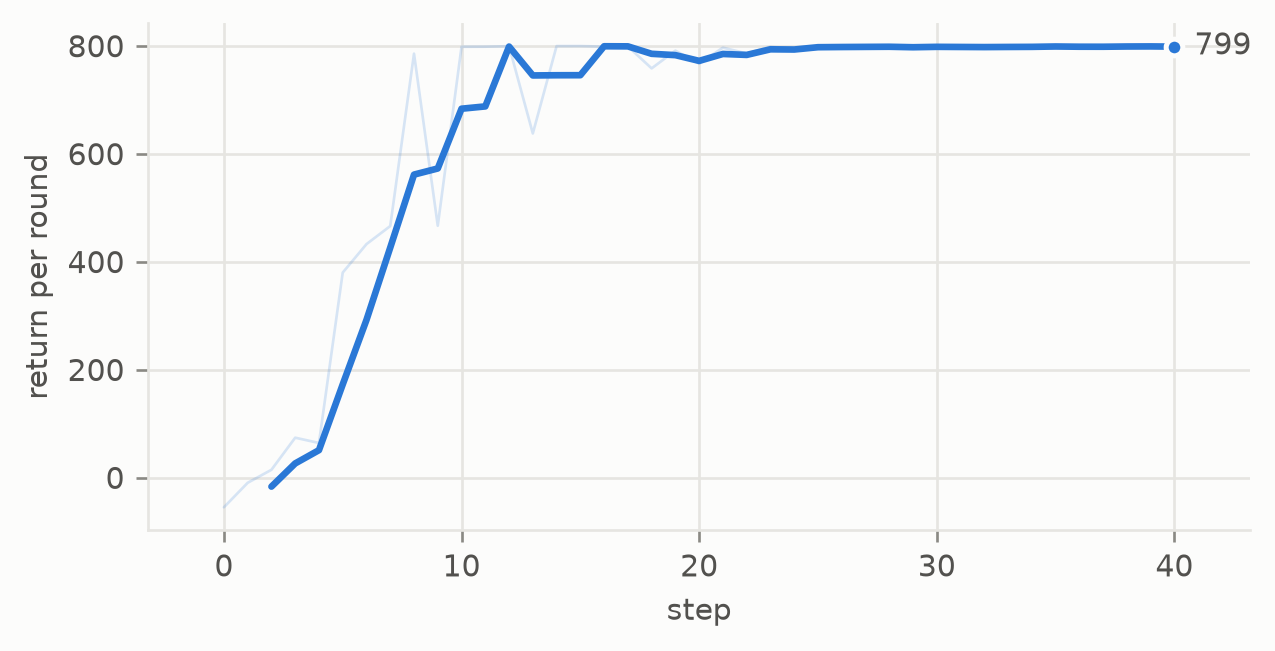

In [5]:
rounds = list(range(len(history)))
plots.curves({"episode return": (rounds, [h[0] for h in history])}, smooth=3, logy=False, ylabel="return per round")

## Evaluation

16 new seeded episodes for each of three policies: MPPI over the world model without exploration noise, the policy prior alone (its mean action, no search) and random actions.

TD-MPC2 + MPPI  return   799.2 ±   0.0   success 1.00


policy prior    return   799.4 ±   0.0   success 1.00
random actions  return   -55.4 ±   3.2   success 0.06


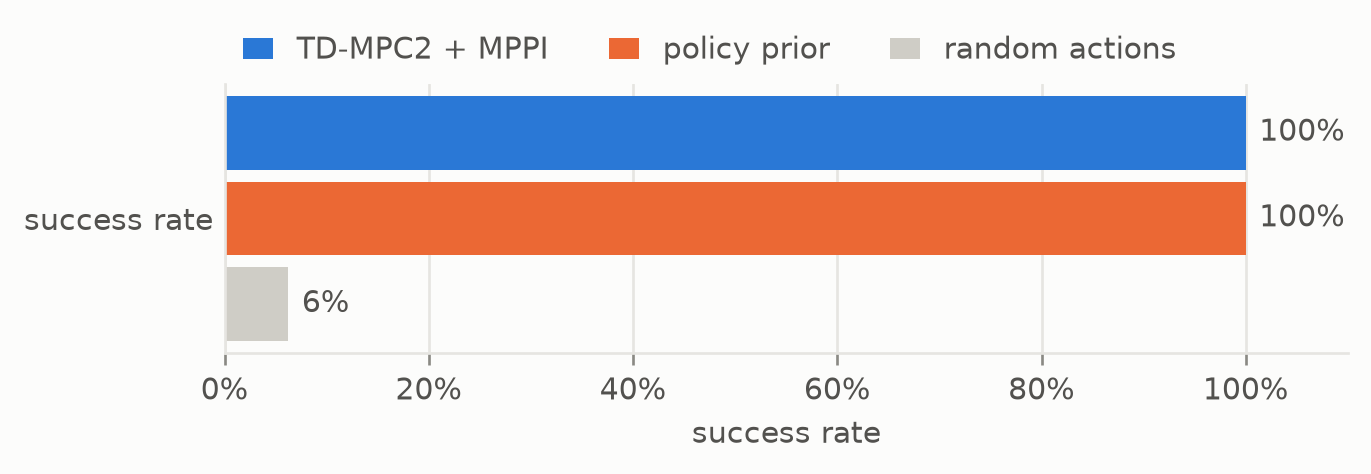

In [6]:
def prior(obs):
    return model.pi(model.encode(obs.to(device)[:, None])[:, 0])[1]["mean"].cpu()


results, video = {}, None
with torch.no_grad():
    for name, policy in (
        ("TD-MPC2 + MPPI", lambda obs: act(obs, explore=False)),
        ("policy prior", prior),
        ("random actions", random_policy),
    ):
        frames = 4 if name == "TD-MPC2 + MPPI" else 0
        returns, success, clip = collect(policy, seed=10_000, frames=frames)
        video = clip if frames else video
        results[name] = {"return": returns.mean().item(), "success": success.float().mean().item()}
        print(f"{name:15s} return {returns.mean():7.1f} ± {returns.std():5.1f}   success {success.float().mean():.2f}")
plots.bars({"success rate": {k: v["success"] for k, v in results.items()}}, xlabel="success rate", baseline="random actions")

Four of the planned evaluation episodes.


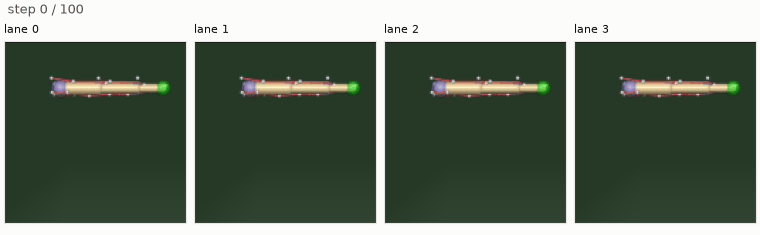

In [7]:
step = max(video.size(1) // 60, 1)
plots.episodes(video[:, ::step], titles=[f"lane {i}" for i in range(4)], fps=8)

This is a small baseline. TD-MPC2's reference runs use a 512-dimensional latent, one update per environment step and up to millions of steps; `observation="rgb"` with `pixel_encoder` trains from images. Any other task works the same way: `MyoSuite(name)` takes the suite's own task names, and `list_envs(backend="myosuite")` lists the registered ones.